# 🥬 FreshVision — Pre-Visual Food Waste Prevention
### *Don't detect waste. Prevent it before it happens.*

**Team DeeDos · PS4: Predicting the Unseen — Pre-Visual Food Waste Mitigation**

FreshVision is a computer vision and inventory intelligence prototype that identifies **potentially at-risk food batches** *before* spoilage is obvious, explains why, and lets staff **simulate waste-prevention strategies** before acting.

| | |
|---|---|
| 🌐 **Live prototype** | https://freshvision-nine.vercel.app/ |
| ▶️ **Demo video** | https://youtu.be/4cgehACaUok |
| 💻 **Source code** | https://github.com/keithdias07/FreshVision |

This notebook explains what the prototype does and **re-implements its core logic in Python** so you can run it, inspect it, and change it. The numbers match the web app, which is written in React + TypeScript.

> ⚠️ **Honesty note.** All inventory values are **demo data**. Risk scores are **heuristic estimates**, not calibrated predictions. Scenarios are **model outputs**, not measured waste avoided. The image analysis uses **hand-crafted colour/texture heuristics**, not a trained spoilage detector.

## Contents
1. [How the system works](#how)
2. [Demo inventory](#inventory)
3. [Explainable risk engine](#risk)
4. [Image inspection (computer vision heuristics)](#vision)
5. [Counterfactual waste-prevention simulator — the USP](#sim)
6. [Actionable recommendations & food-safety rules](#recs)
7. [3D inventory digital twin](#twin)
8. [Limitations & roadmap](#limits)

*Run all cells with **Runtime → Run all**. No installs, API keys or GPU are needed.*

<a name="how"></a>
## 1. How the system works

```
 INPUTS                         PROCESSING (in the browser, no backend)              OUTPUTS
 ─────────────────────────      ───────────────────────────────────────────          ──────────────────────────
 Produce photo  ───────────▶   Image heuristics → visual score (0–100) ──┐
 Inventory age & quantity ─┐                                              ├──▶ Risk score + factor breakdown
 Storage temp & humidity  ─┼─▶ Explainable risk engine ───────────────────┤   Food-safety holds
 Consumption rate         ─┘   (weighted, configurable, renormalised)     ├──▶ Ranked batches & charts
                                                                          ├──▶ Counterfactual scenarios
                               Counterfactual simulator ◀── interventions ┘   Prioritised actions
                                                                               3D storeroom digital twin
```

**Key idea:** visible spoilage is a *late* signal. Storage age, temperature history and the consumption rate change **before** the surface does. FreshVision combines those signals with optional visual evidence to flag batches that need attention early.

In [1]:
# Setup: everything used here is pre-installed in Google Colab
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import rgb_to_hsv
from PIL import Image, ImageDraw, ImageFilter

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
GREEN, CREAM, CHARCOAL = "#3f7d4e", "#f6f2e8", "#1d2420"
STATUS_COLOR = {"hold": "#6b2135", "critical": "#c2412d", "high": "#d9772b", "moderate": "#c9a227", "low": "#5c9a6b"}
STATUS_LABEL = {"hold": "Hold · inspect", "critical": "Critical", "high": "High", "moderate": "Moderate", "low": "Low"}
clamp01 = lambda v: max(0.0, min(1.0, v))
js_round = lambda v: int(math.floor(v + 0.5))  # JavaScript Math.round semantics
print("Ready ✔")

Ready ✔


<a name="inventory"></a>
## 2. Demo inventory

Ten produce batches (**illustrative demo data**, the same as in the web app). For each batch we track:
- **quantity** and **storage age** vs a reference **shelf life**
- **storage zone**, **target vs logged temperature**, **cold-chain excursion hours** and **humidity**
- **consumption rate** (kg/day from recent menu usage)
- **TCS flag**: items that need temperature control for safety (cut fruit, leafy greens)

In [2]:
DEMO_BATCHES = [
  dict(id="B-1042", food="Strawberries",     emoji="🍓", quantityKg=18, ageDays=3,  shelfLifeDays=5,  storage="Walk-in chiller", idealTempC=2,  avgTempC=5.5, excursionHours=3, humidityPct=82, idealHumidityPct=92, consumptionKgPerDay=3.2, tcs=False),
  dict(id="B-1043", food="Baby spinach",     emoji="🥬", quantityKg=12, ageDays=4,  shelfLifeDays=7,  storage="Reach-in fridge", idealTempC=2,  avgTempC=6.8, excursionHours=7, humidityPct=88, idealHumidityPct=95, consumptionKgPerDay=1.4, tcs=True),
  dict(id="B-1044", food="Bananas",          emoji="🍌", quantityKg=30, ageDays=3,  shelfLifeDays=7,  storage="Ambient rack",    idealTempC=14, avgTempC=18,  excursionHours=0, humidityPct=60, idealHumidityPct=90, consumptionKgPerDay=4.5, tcs=False),
  dict(id="B-1045", food="Roma tomatoes",    emoji="🍅", quantityKg=25, ageDays=5,  shelfLifeDays=10, storage="Ambient rack",    idealTempC=13, avgTempC=19,  excursionHours=0, humidityPct=70, idealHumidityPct=90, consumptionKgPerDay=3.0, tcs=False),
  dict(id="B-1046", food="Avocados",         emoji="🥑", quantityKg=14, ageDays=6,  shelfLifeDays=9,  storage="Produce cooler",  idealTempC=7,  avgTempC=7.5, excursionHours=0, humidityPct=88, idealHumidityPct=90, consumptionKgPerDay=1.1, tcs=False),
  dict(id="B-1047", food="Carrots",          emoji="🥕", quantityKg=40, ageDays=9,  shelfLifeDays=28, storage="Walk-in chiller", idealTempC=1,  avgTempC=2,   excursionHours=0, humidityPct=94, idealHumidityPct=95, consumptionKgPerDay=2.8, tcs=False),
  dict(id="B-1048", food="Cut melon (prep)", emoji="🍈", quantityKg=6,  ageDays=2,  shelfLifeDays=3,  storage="Reach-in fridge", idealTempC=3,  avgTempC=6,   excursionHours=5, humidityPct=90, idealHumidityPct=90, consumptionKgPerDay=1.5, tcs=True),
  dict(id="B-1049", food="Apples (Gala)",    emoji="🍎", quantityKg=35, ageDays=12, shelfLifeDays=45, storage="Walk-in chiller", idealTempC=1,  avgTempC=1.5, excursionHours=0, humidityPct=92, idealHumidityPct=92, consumptionKgPerDay=1.9, tcs=False),
  dict(id="B-1050", food="Mushrooms",        emoji="🍄", quantityKg=8,  ageDays=4,  shelfLifeDays=6,  storage="Reach-in fridge", idealTempC=2,  avgTempC=4,   excursionHours=1, humidityPct=80, idealHumidityPct=92, consumptionKgPerDay=0.9, tcs=False),
  dict(id="B-1051", food="Bell peppers",     emoji="🫑", quantityKg=16, ageDays=3,  shelfLifeDays=14, storage="Produce cooler",  idealTempC=8,  avgTempC=8,   excursionHours=0, humidityPct=90, idealHumidityPct=92, consumptionKgPerDay=1.6, tcs=False),
]
inv = pd.DataFrame(DEMO_BATCHES).set_index("id")
inv[["food", "quantityKg", "ageDays", "shelfLifeDays", "storage", "avgTempC", "idealTempC", "excursionHours", "consumptionKgPerDay", "tcs"]]

,food,quantityKg,ageDays,shelfLifeDays,storage,avgTempC,idealTempC,excursionHours,consumptionKgPerDay,tcs
id,,,,,,,,,,
B-1042,Strawberries,18,3,5,Walk-in chiller,5.5,2,3,3.2,False
B-1043,Baby spinach,12,4,7,Reach-in fridge,6.8,2,7,1.4,True
B-1044,Bananas,30,3,7,Ambient rack,18.0,14,0,4.5,False
B-1045,Roma tomatoes,25,5,10,Ambient rack,19.0,13,0,3.0,False
B-1046,Avocados,14,6,9,Produce cooler,7.5,7,0,1.1,False
B-1047,Carrots,40,9,28,Walk-in chiller,2.0,1,0,2.8,False
B-1048,Cut melon (prep),6,2,3,Reach-in fridge,6.0,3,5,1.5,True
B-1049,Apples (Gala),35,12,45,Walk-in chiller,1.5,1,0,1.9,False
B-1050,Mushrooms,8,4,6,Reach-in fridge,4.0,2,1,0.9,False


<a name="risk"></a>
## 3. Explainable risk engine

Every batch gets an **inventory-risk score (0–100)**: a transparent **weighted sum of five normalised factors**. Each factor is scored 0–100.

| Factor | How it is scored | Default weight |
|---|---|---|
| **Storage age** | % of reference shelf life used, **temperature-adjusted**: `age × Q10^(ΔT/10)` | 0.30 |
| **Temperature deviation** | 70% from \|forward temp − target\| / 6 °C, plus 30% from excursion hours / 8 h | 0.25 |
| **Humidity deviation** | \|RH − target RH\| / 25 % | 0.10 |
| **Demand shortfall** | share of stock **not** used before usable life runs out, at the current rate | 0.20 |
| **Visual indicators** | image-heuristic score, *only if a photo was analysed* | 0.15 |

- If a batch has no photo, the visual weight is dropped and the other weights are **renormalised** to sum to 1.
- **Ageing assumption:** a Q10-style multiplier of `2.5^(ΔT/10)`. Each +10 °C above target makes produce age ~2.5× faster. This is an *uncalibrated assumption*.
- **Projected unused kg** = `stock − daily usage × remaining usable days` (floored at 0).

**Food-safety rules override the score.** A batch is put on **HOLD** if:
1. it is past its estimated usable life, **or**
2. it is a TCS item with ≥ 4 h of logged temperature excursions, **or**
3. its visual heuristic score is ≥ 70 (manual inspection required).

A low visual score **never** clears a hold.

In [3]:
DEFAULT_CONFIG = dict(
    weights=dict(age=0.30, temperature=0.25, humidity=0.10, demand=0.20, visual=0.15),
    q10=2.5,                    # ageing multiplier per +10 °C above target (assumption)
    tcsExcursionHoldHours=4,    # set per your HACCP plan
    visualHoldScore=70,
)

def assess(b, cfg=DEFAULT_CONFIG, ov=None):
    # Score one batch. `ov` holds scenario overrides (forward temp/humidity, usage rate, quantity).
    ov = ov or {}
    temp = ov.get("avgTempC", b["avgTempC"]); hum = ov.get("humidityPct", b["humidityPct"])
    rate = ov.get("consumptionKgPerDay", b["consumptionKgPerDay"]); qty = ov.get("quantityKg", b["quantityKg"])

    # Life already used depends on HISTORICAL temperature (the past can't be changed)
    hist_mult = cfg["q10"] ** (max(0, b["avgTempC"] - b["idealTempC"]) / 10)
    life_used = b["ageDays"] * hist_mult
    # Remaining life runs at the FORWARD (possibly corrected) temperature
    fwd_dev = temp - b["idealTempC"]
    fwd_mult = cfg["q10"] ** (max(0, fwd_dev) / 10)
    remaining = max(0.0, (b["shelfLifeDays"] - life_used) / fwd_mult)
    life_used_pct = clamp01(life_used / b["shelfLifeDays"]) * 100
    days_to_deplete = qty / rate if rate > 0 else math.inf

    unused_frac = 1.0 if remaining <= 0 else clamp01(1 - rate * remaining / max(qty, 1e-6))
    raw = [
        ("age", "Storage age", life_used_pct),
        ("temperature", "Temperature deviation", (clamp01(abs(fwd_dev) / 6) * 0.7 + clamp01(b["excursionHours"] / 8) * 0.3) * 100),
        ("humidity", "Humidity deviation", clamp01(abs(hum - b["idealHumidityPct"]) / 25) * 100),
        ("demand", "Demand shortfall", unused_frac * 100),
    ]
    if b.get("visualScore") is not None:
        raw.append(("visual", "Visual indicators", b["visualScore"]))
    w_sum = sum(cfg["weights"][k] for k, _, _ in raw) or 1
    factors = [dict(key=k, label=l, score=s, weight=cfg["weights"][k] / w_sum, points=s * cfg["weights"][k] / w_sum) for k, l, s in raw]
    score = js_round(sum(f["points"] for f in factors))

    holds = []
    if life_used >= b["shelfLifeDays"]: holds.append("Past estimated usable life")
    if b["tcs"] and b["excursionHours"] >= cfg["tcsExcursionHoldHours"]: holds.append(f"TCS item with {b['excursionHours']} h excursions")
    if b.get("visualScore") is not None and b["visualScore"] >= cfg["visualHoldScore"]: holds.append("High visual heuristic, so inspect")

    status = "hold" if holds else "critical" if score >= 65 else "high" if score >= 48 else "moderate" if score >= 30 else "low"
    at_risk = qty if status == "hold" else max(0.0, qty - rate * remaining)
    return dict(batch=b, score=score, factors=factors, status=status, holds=holds, life_used_pct=life_used_pct,
                remaining_days=remaining, days_to_deplete=days_to_deplete, ageing_mult=fwd_mult, at_risk_kg=at_risk)

def ranked_table(batches, cfg=DEFAULT_CONFIG):
    rows = [assess(b, cfg) for b in batches]
    rows.sort(key=lambda a: (a["status"] == "hold") * 1000 + a["score"], reverse=True)
    return pd.DataFrame([{
        "batch": f"{a['batch']['emoji']} {a['batch']['food']}", "id": a["batch"]["id"],
        "risk score": a["score"], "status": STATUS_LABEL[a["status"]],
        "life used %": round(a["life_used_pct"]), "days left": round(a["remaining_days"], 1),
        "projected unused kg": round(a["at_risk_kg"], 1), "hold reason": "; ".join(a["holds"]) or "—",
    } for a in rows]).set_index("id")

ranked_table(DEMO_BATCHES)

,batch,risk score,status,life used %,days left,projected unused kg,hold reason
id,,,,,,,
B-1043,🥬 Baby spinach,81,Hold · inspect,89,0.5,12.0,TCS item with 7 h excursions
B-1048,🍈 Cut melon (prep),69,Hold · inspect,88,0.3,6.0,TCS item with 5 h excursions
B-1045,🍅 Roma tomatoes,82,Critical,87,0.8,22.7,—
B-1042,🍓 Strawberries,70,Critical,83,0.6,16.0,—
B-1044,🍌 Bananas,64,High,62,1.9,21.7,—
B-1050,🍄 Mushrooms,63,High,80,1.0,7.1,—
B-1046,🥑 Avocados,46,Moderate,70,2.6,11.1,—
B-1047,🥕 Carrots,16,Low,35,16.5,0.0,—
B-1049,🍎 Apples (Gala),12,Low,28,31.0,0.0,—


### Why does a batch score what it scores?

Every score can be traced back to its factors. Below is the breakdown for **Bananas (B-1044)**: stored at 18 °C against a 14 °C target, so the model ages them about 1.44× faster.

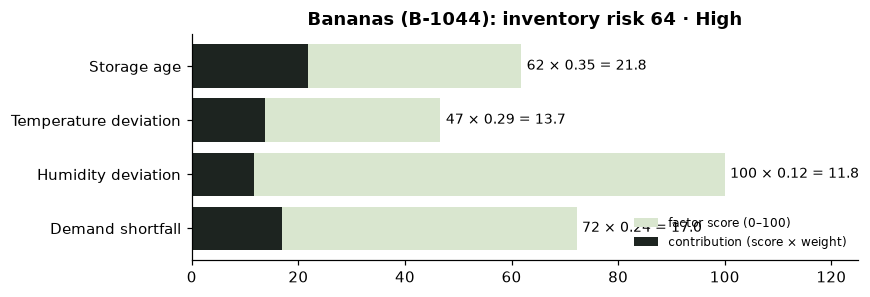

Ageing multiplier 1.44× · 1.9 days left · 6.7 days to use the stock → 21.7 kg projected unused


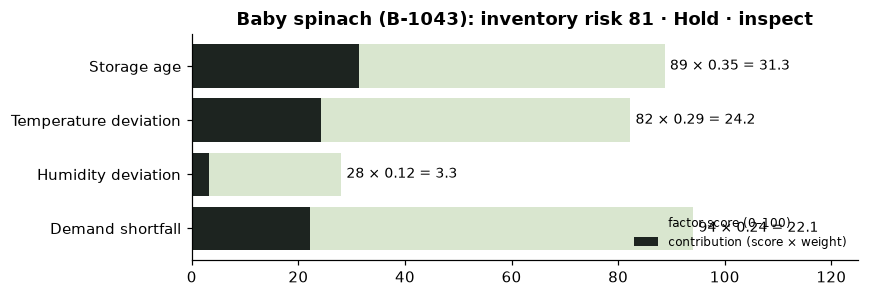

Ageing multiplier 1.55× · 0.5 days left · 8.6 days to use the stock → 12.0 kg projected unused
⛔ FOOD-SAFETY HOLD: TCS item with 7 h excursions


In [4]:
def explain(batch_id, batches=DEMO_BATCHES, cfg=DEFAULT_CONFIG):
    a = assess(next(b for b in batches if b["id"] == batch_id), cfg)
    b = a["batch"]
    fig, ax = plt.subplots(figsize=(8, 2.8))
    labels = [f["label"] for f in a["factors"]][::-1]
    ax.barh(labels, [f["score"] for f in a["factors"]][::-1], color="#d9e6cf", label="factor score (0–100)")
    ax.barh(labels, [f["points"] for f in a["factors"]][::-1], color=CHARCOAL, label="contribution (score × weight)")
    for i, f in enumerate(a["factors"][::-1]):
        ax.text(f["score"] + 1, i, f"{f['score']:.0f} × {f['weight']:.2f} = {f['points']:.1f}", va="center", fontsize=9)
    ax.set_xlim(0, 125); ax.legend(loc="lower right", fontsize=8, frameon=False)
    ax.set_title(f"{b['food']} ({b['id']}): inventory risk {a['score']} · {STATUS_LABEL[a['status']]}")
    plt.tight_layout(); plt.show()
    print(f"Ageing multiplier {a['ageing_mult']:.2f}× · {a['remaining_days']:.1f} days left · "
          f"{a['days_to_deplete']:.1f} days to use the stock → {a['at_risk_kg']:.1f} kg projected unused")
    if a["holds"]: print("⛔ FOOD-SAFETY HOLD:", "; ".join(a["holds"]))

explain("B-1044")
explain("B-1043")   # baby spinach: the safety rule overrides the score

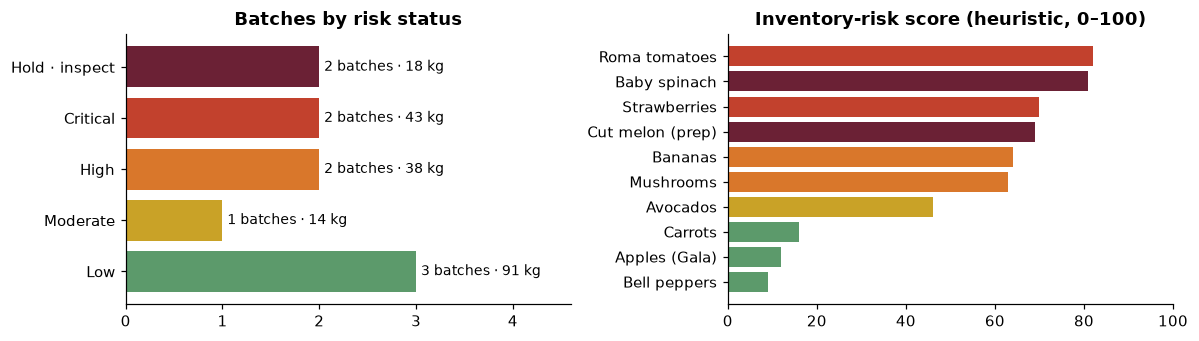

In [5]:
# Risk distribution across the inventory (same chart idea as the dashboard)
assessed = [assess(b) for b in DEMO_BATCHES]
order = ["hold", "critical", "high", "moderate", "low"]
counts = [sum(a["status"] == s for a in assessed) for s in order]
kg = [sum(a["batch"]["quantityKg"] for a in assessed if a["status"] == s) for s in order]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.2))
ax1.barh([STATUS_LABEL[s] for s in order][::-1], counts[::-1], color=[STATUS_COLOR[s] for s in order][::-1])
for i, (c, k) in enumerate(zip(counts[::-1], kg[::-1])): ax1.text(c + 0.05, i, f"{c} batches · {k} kg", va="center", fontsize=9)
ax1.set_title("Batches by risk status"); ax1.set_xlim(0, max(counts) + 1.6)
srt = sorted(assessed, key=lambda a: a["score"])
ax2.barh([a["batch"]["food"] for a in srt], [a["score"] for a in srt], color=[STATUS_COLOR[a["status"]] for a in srt])
ax2.set_title("Inventory-risk score (heuristic, 0–100)"); ax2.set_xlim(0, 100)
plt.tight_layout(); plt.show()

**Try it:** the model is fully configurable. Change a weight or the Q10 assumption and re-rank:

In [6]:
custom = {**DEFAULT_CONFIG, "q10": 3.0, "weights": {**DEFAULT_CONFIG["weights"], "temperature": 0.40}}
ranked_table(DEMO_BATCHES, custom)[["batch", "risk score", "status", "projected unused kg"]]

,batch,risk score,status,projected unused kg
id,,,,
B-1043,🥬 Baby spinach,84,Hold · inspect,12.0
B-1048,🍈 Cut melon (prep),69,Hold · inspect,6.0
B-1045,🍅 Roma tomatoes,85,Critical,24.5
B-1042,🍓 Strawberries,70,Critical,16.7
B-1044,🍌 Bananas,64,High,23.2
B-1050,🍄 Mushrooms,59,High,7.3
B-1046,🥑 Avocados,40,Moderate,11.2
B-1047,🥕 Carrots,16,Low,0.0
B-1049,🍎 Apples (Gala),11,Low,0.0


<a name="vision"></a>
## 4. Image inspection: computer vision heuristics

The web app analyses a produce photo **locally in the browser**, with nothing uploaded to a server. The pipeline is reproduced below with NumPy:

1. **Downsample** to ≤ 320 px on the long side.
2. **Segment the produce from the background.** Model the background colour from the image's border, then mark pixels far from it as produce.
3. **Convert to HSV** and flag pixels:
   - 🔴 **dark lesions**: very low brightness (V < 0.22)
   - 🟠 **brown discoloration**: hue 12–42°, saturation > 0.35, V < 0.5 (bruising, oxidation)
   - 🔵 **pale / whitish patches**: low saturation, mid-high brightness (possible mould bloom, *or glare*)
4. **Colour variation**: circular hue dispersion plus brightness spread.
5. **Surface texture**: mean absolute Laplacian (wrinkling, pitting, fuzz).
6. **Visual score (0–100)**: a weighted sum of the five normalised indicators.

> These are **hand-crafted heuristics, not a trained spoilage detector.** Shadows, glare, packaging and naturally multi-coloured produce can fool them. The web app *optionally* runs **MobileNet v2** (TensorFlow.js) to name the produce type, but MobileNet says nothing about freshness.

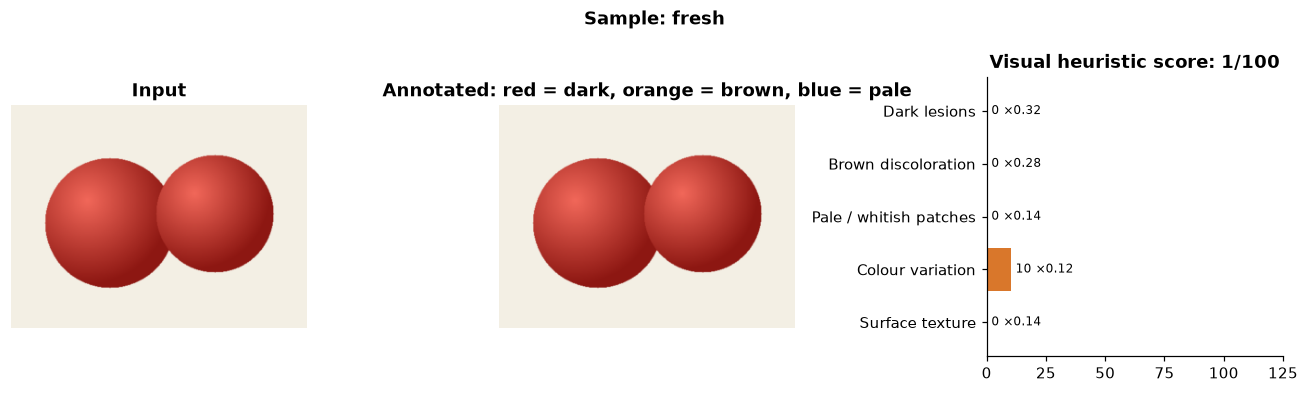

Produce area 36% (border-colour segmentation)


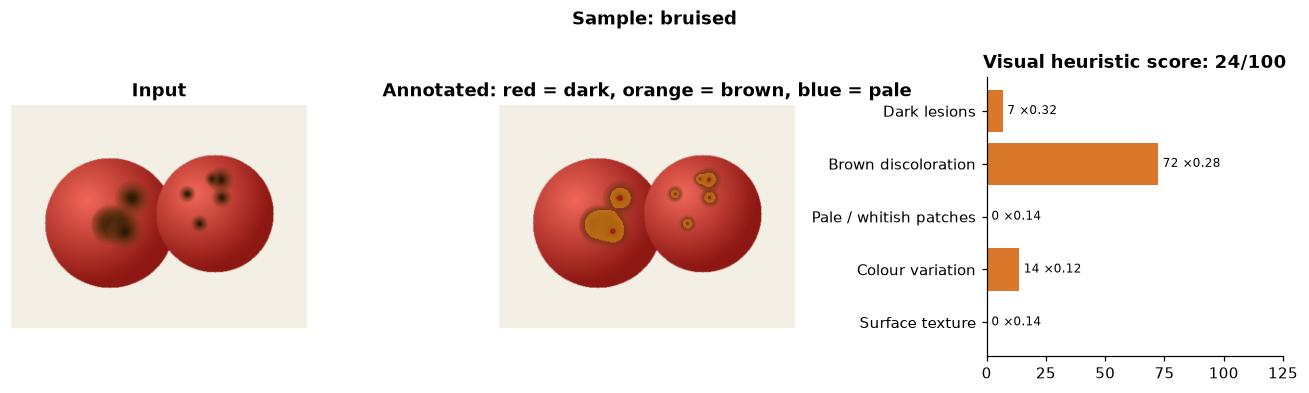

Produce area 36% (border-colour segmentation)


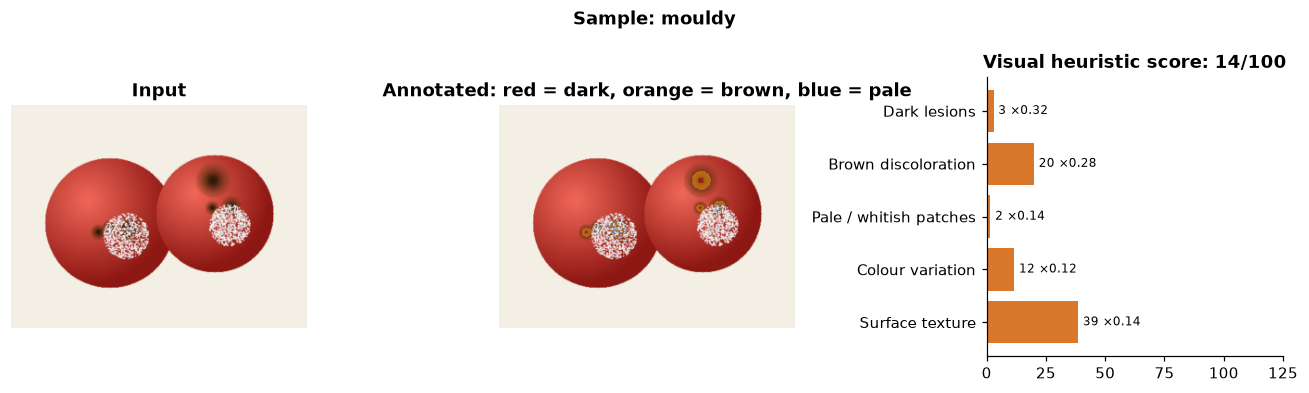

Produce area 34% (border-colour segmentation)


In [7]:
def make_sample_image(kind="bruised", size=(480, 360), seed=13):
    # Procedurally drawn sample (two red fruits on a cream background), the same idea as the web app's samples.
    W, H = size
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    img = np.ones((H, W, 3), np.float32) * np.array([243, 239, 228], np.float32)
    rng = np.random.default_rng({"fresh": 7, "bruised": 13, "mouldy": 29}[kind])
    for cx, cy, r in [(160, 190, 105), (330, 175, 95)]:
        d = np.sqrt((xx - cx) ** 2 + (yy - cy) ** 2)
        inside = d <= r
        hl = np.sqrt((xx - (cx - 0.35 * r)) ** 2 + (yy - (cy - 0.35 * r)) ** 2) / r   # radial shading from a highlight
        t = np.clip(hl / 1.3, 0, 1)[..., None]
        shade = (1 - t) * np.array([242, 104, 90]) + t * np.array([141, 23, 18])
        img[inside] = shade[inside]
        if kind != "fresh":
            for _ in range(5 if kind == "bruised" else 3):
                a, dd = rng.uniform(0, 2 * np.pi), rng.uniform(0, 0.6) * r
                sx, sy, sr = cx + np.cos(a) * dd, cy + np.sin(a) * dd, r * rng.uniform(0.12, 0.30)
                ds = np.sqrt((xx - sx) ** 2 + (yy - sy) ** 2) / sr
                m = (ds < 1) & inside
                k = np.clip(ds, 0, 1)[..., None]
                spot = (1 - k) * np.array([43, 22, 7]) + k * np.array([120, 60, 20])
                alpha = np.clip(1.2 - ds, 0, 1)[..., None]
                img[m] = (alpha * spot + (1 - alpha) * img)[m]
        if kind == "mouldy":
            n = 900; a = rng.uniform(0, 2 * np.pi, n); dd = np.sqrt(rng.uniform(0, 1, n)) * r * 0.35
            for px, py in zip((cx + 0.25 * r + np.cos(a) * dd).astype(int), (cy + 0.2 * r + np.sin(a) * dd).astype(int)):
                img[py:py + 2, px:px + 2] = rng.uniform(220, 250, 3)
    return Image.fromarray(np.clip(img, 0, 255).astype(np.uint8))


def analyze_image(pil_img):
    # Port of the prototype's vision.ts heuristics. Returns the score, indicators and an annotated overlay.
    im = pil_img.convert("RGB")
    s = min(1.0, 320 / max(im.size))
    im = im.resize((max(8, round(im.width * s)), max(8, round(im.height * s))), Image.BILINEAR)
    rgb = np.asarray(im).astype(np.float32); H, W, _ = rgb.shape

    # 1) background model from the border frame
    bw = max(2, round(min(W, H) * 0.04))
    border = np.zeros((H, W), bool); border[:bw] = border[-bw:] = True; border[:, :bw] = border[:, -bw:] = True
    bg_mean = rgb[border].mean(0)
    bg_std = np.sqrt(((rgb[border] - bg_mean) ** 2).mean())
    dist = np.sqrt(((rgb - bg_mean) ** 2).mean(-1))
    fg = dist > max(38, 2.5 * bg_std)
    fallback = fg.mean() < 0.08 or fg.mean() > 0.97
    if fallback: fg[:] = True                       # busy/close-up shot: use the whole frame

    hsv = rgb_to_hsv(rgb / 255.0); h, sat, v = hsv[..., 0] * 360, hsv[..., 1], hsv[..., 2]
    gray = 0.299 * rgb[..., 0] + 0.587 * rgb[..., 1] + 0.114 * rgb[..., 2]

    # 2) pixel flags inside the produce mask (priority: dark > brown > pale)
    dark = fg & (v < 0.22)
    brown = fg & ~dark & (h >= 12) & (h <= 42) & (sat > 0.35) & (v < 0.5)
    pale = fg & ~dark & ~brown & (sat < 0.12) & (v > 0.55) & (v < 0.93)
    n = max(1, fg.sum())
    dark_f, brown_f, pale_f = dark.sum() / n, brown.sum() / n, pale.sum() / n

    # 3) colour variation: circular hue dispersion weighted by saturation, plus brightness spread
    satpx = fg & (sat > 0.15)
    rad = np.deg2rad(h[satpx])
    R = np.hypot((np.cos(rad) * sat[satpx]).sum(), (np.sin(rad) * sat[satpx]).sum()) / max(1, satpx.sum())
    hue_disp = clamp01(1 - R / 0.6)
    v_std = v[fg].std()
    hist = np.bincount((h[satpx] // 30).astype(int) % 12, minlength=12) / max(1, satpx.sum())

    # 4) texture: mean |Laplacian| inside the produce
    lap = np.abs(4 * gray[1:-1, 1:-1] - gray[:-2, 1:-1] - gray[2:, 1:-1] - gray[1:-1, :-2] - gray[1:-1, 2:])
    texture = lap[fg[1:-1, 1:-1]].mean() if fg[1:-1, 1:-1].any() else 0

    ind = [
        ("Dark lesions", dark_f, clamp01(dark_f / 0.06) * 100, 0.32),
        ("Brown discoloration", brown_f, clamp01(brown_f / 0.10) * 100, 0.28),
        ("Pale / whitish patches", pale_f, clamp01(pale_f / 0.15) * 100, 0.14),
        ("Colour variation", hue_disp, clamp01(hue_disp * 0.7 + v_std / 0.3 * 0.3) * 100, 0.12),
        ("Surface texture", texture, clamp01((texture - 6) / 22) * 100, 0.14),
    ]
    score = js_round(sum(c * w for _, _, c, w in ind))

    overlay = np.zeros((H, W, 4), np.uint8)
    overlay[dark] = (220, 38, 38, 160); overlay[brown] = (234, 140, 20, 160); overlay[pale] = (96, 165, 250, 160)
    return dict(score=score, indicators=ind, fg_pct=round(fg.mean() * 100), fallback=fallback,
                hue_hist=hist, image=np.asarray(im), overlay=overlay)


def show_analysis(pil_img, title=""):
    r = analyze_image(pil_img)
    fig = plt.figure(figsize=(12, 3.6))
    ax0 = fig.add_subplot(1, 3, 1); ax0.imshow(r["image"]); ax0.set_title("Input"); ax0.axis("off")
    ax1 = fig.add_subplot(1, 3, 2); ax1.imshow(r["image"]); ax1.imshow(r["overlay"]); ax1.axis("off")
    ax1.set_title("Annotated: red = dark, orange = brown, blue = pale")
    ax2 = fig.add_subplot(1, 3, 3)
    names = [i[0] for i in r["indicators"]][::-1]
    ax2.barh(names, [i[2] for i in r["indicators"]][::-1], color="#d9772b")
    for k, (_, _, c, w) in enumerate(r["indicators"][::-1]): ax2.text(c + 2, k, f"{c:.0f} ×{w}", va="center", fontsize=8)
    ax2.set_xlim(0, 125); ax2.set_title(f"Visual heuristic score: {r['score']}/100")
    fig.suptitle(title, fontweight="bold"); plt.tight_layout(); plt.show()
    print(f"Produce area {r['fg_pct']}%" + (" (background not separable, so the whole frame was used)" if r["fallback"] else " (border-colour segmentation)"))
    return r

for kind in ["fresh", "bruised", "mouldy"]:
    show_analysis(make_sample_image(kind), f"Sample: {kind}")

### Try your own produce photo
Run the cell below in Colab and upload a JPG or PNG. Outside Colab, set `path` to a local file instead.

In [ ]:
try:
    from google.colab import files
    up = files.upload()
    for name in up:
        user_result = show_analysis(Image.open(name), f"Your image: {name}")
except ImportError:
    print("Not running in Colab. To analyse a local file:  show_analysis(Image.open('path/to/photo.jpg'))")
except Exception as e:
    print("Upload skipped or failed:", e)

### Fusing vision with inventory context
The visual score is kept **separate** from the inventory-risk score. When a photo is attached to a batch, it is added as a **fifth factor** (weight 0.15), and the other weights are renormalised. Here we attach the bruised sample's score to the strawberries:

Strawberries before photo: risk 70 (Critical)
Strawberries with visual score 24: risk 63 (High)


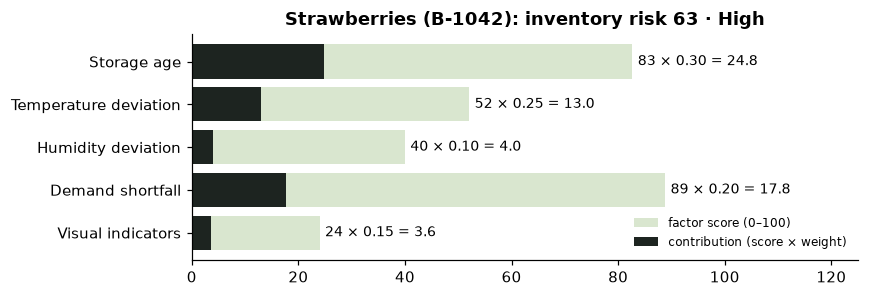

Ageing multiplier 1.38× · 0.6 days left · 5.6 days to use the stock → 16.0 kg projected unused


In [9]:
vis = analyze_image(make_sample_image("bruised"))["score"]
with_photo = [dict(b, visualScore=vis) if b["id"] == "B-1042" else b for b in DEMO_BATCHES]
before, after = assess(DEMO_BATCHES[0]), assess(with_photo[0])
print(f"Strawberries before photo: risk {before['score']} ({STATUS_LABEL[before['status']]})")
print(f"Strawberries with visual score {vis}: risk {after['score']} ({STATUS_LABEL[after['status']]})")
explain("B-1042", with_photo)

<a name="sim"></a>
## 5. Counterfactual waste-prevention simulator: the USP

Most tools stop at *"this batch is at risk."* FreshVision asks **"what if we act today?"**

Users compare the **baseline plan** with an **intervention** and see how **projected unused stock** changes. Possible interventions:
- **Prioritise on the menu**: multiply the daily usage rate (assumes demand can absorb it).
- **Correct storage**: move to the target temperature/humidity *from today*. Life already used cannot be undone.
- **Redistribute / donate**: transfer kg to another site (assumes a safe recipient).

**Safety gate:** a batch on HOLD can never be prioritised or transferred in the model. Only storage correction applies to it.

> This is a **model-based scenario on demo data**, not measured waste avoided.

Baseline projected unused: 96.6 kg  →  scenario: 83.3 kg  (change -13.3 kg, -14%)   [simulated]


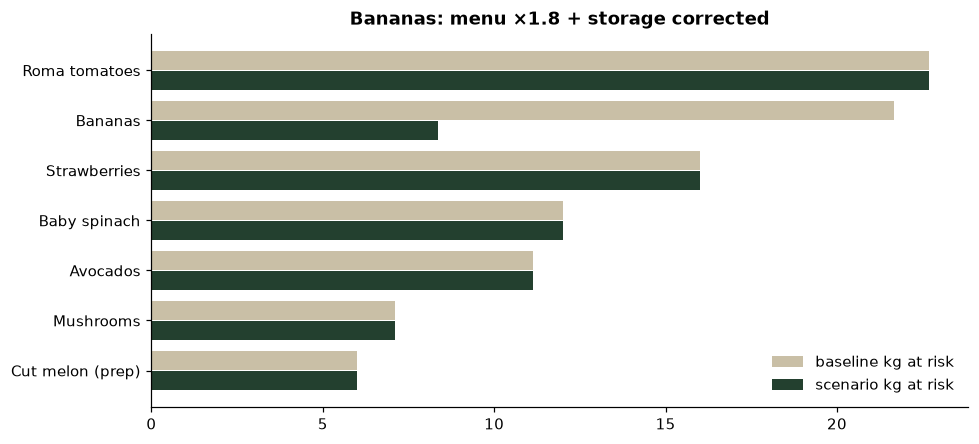

In [10]:
def run_scenario(batches, plan, cfg=DEFAULT_CONFIG):
    rows = []
    for b in batches:
        base = assess(b, cfg); iv = plan.get(b["id"]); blocked = []
        if not iv: rows.append(dict(id=b["id"], food=b["food"], base=base, scen=base, blocked=blocked)); continue
        ov = {}
        if iv.get("fixStorage"): ov.update(avgTempC=b["idealTempC"], humidityPct=b["idealHumidityPct"])
        if base["status"] == "hold":
            if iv.get("menuBoost", 1) != 1: blocked.append("menu prioritisation blocked (safety hold)")
            if iv.get("transferKg", 0) > 0: blocked.append("transfer blocked (safety hold)")
        else:
            if iv.get("menuBoost", 1) != 1: ov["consumptionKgPerDay"] = b["consumptionKgPerDay"] * iv["menuBoost"]
            if iv.get("transferKg", 0) > 0: ov["quantityKg"] = max(0, b["quantityKg"] - iv["transferKg"])
        rows.append(dict(id=b["id"], food=b["food"], base=base, scen=assess(b, cfg, ov), blocked=blocked))
    return rows

def compare(plan, title="Baseline vs intervention"):
    rows = run_scenario(DEMO_BATCHES, plan)
    base = sum(r["base"]["at_risk_kg"] for r in rows); scen = sum(r["scen"]["at_risk_kg"] for r in rows)
    print(f"Baseline projected unused: {base:.1f} kg  →  scenario: {scen:.1f} kg  "
          f"(change {scen - base:+.1f} kg, {(scen - base) / base * 100:+.0f}%)   [simulated]")
    for r in rows:
        for m in r["blocked"]: print(f"  ⛔ {r['id']} {r['food']}: {m}")
    shown = sorted([r for r in rows if r["base"]["at_risk_kg"] > 0.05 or r["scen"]["at_risk_kg"] > 0.05], key=lambda r: r["base"]["at_risk_kg"])
    y = np.arange(len(shown))
    fig, ax = plt.subplots(figsize=(9, 0.42 * len(shown) + 1.2))
    ax.barh(y + 0.2, [r["base"]["at_risk_kg"] for r in shown], 0.38, color="#c9bfa6", label="baseline kg at risk")
    ax.barh(y - 0.2, [r["scen"]["at_risk_kg"] for r in shown], 0.38, color="#23402f", label="scenario kg at risk")
    ax.set_yticks(y, [r["food"] for r in shown]); ax.legend(frameon=False, loc="lower right"); ax.set_title(title)
    plt.tight_layout(); plt.show()
    return rows

# The scenario shown in the demo: prioritise bananas on today's menu (usage ×1.8) and correct their storage
_ = compare({"B-1044": dict(menuBoost=1.8, fixStorage=True)}, "Bananas: menu ×1.8 + storage corrected")

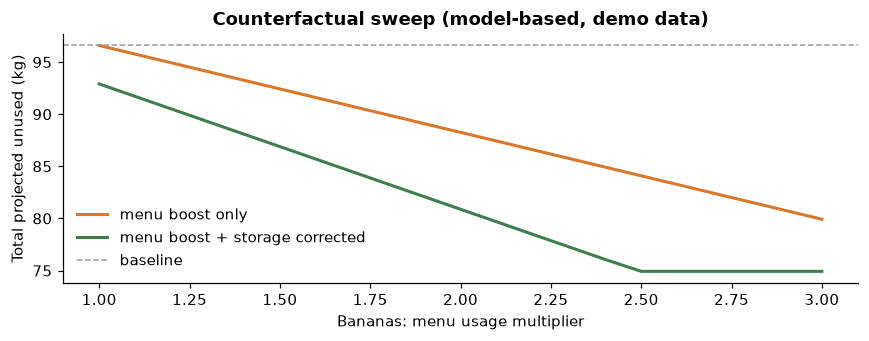

In [11]:
# How projected waste responds as the menu boost increases (bananas, storage corrected vs not)
boosts = np.linspace(1, 3, 21)
def total(plan): return sum(r["scen"]["at_risk_kg"] for r in run_scenario(DEMO_BATCHES, plan))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(boosts, [total({"B-1044": dict(menuBoost=m, fixStorage=False)}) for m in boosts], color="#d9772b", lw=2, label="menu boost only")
ax.plot(boosts, [total({"B-1044": dict(menuBoost=m, fixStorage=True)}) for m in boosts], color=GREEN, lw=2, label="menu boost + storage corrected")
ax.axhline(total({}), color="#999", ls="--", lw=1, label="baseline")
ax.set_xlabel("Bananas: menu usage multiplier"); ax.set_ylabel("Total projected unused (kg)")
ax.set_title("Counterfactual sweep (model-based, demo data)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

Baseline projected unused: 96.6 kg  →  scenario: 96.6 kg  (change +0.0 kg, +0%)   [simulated]
  ⛔ B-1043 Baby spinach: menu prioritisation blocked (safety hold)
  ⛔ B-1043 Baby spinach: transfer blocked (safety hold)


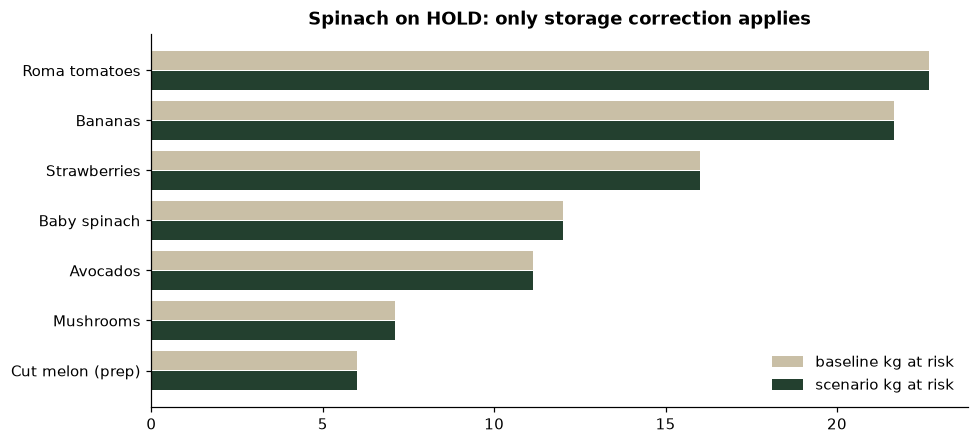

In [12]:
# Safety gate: trying to push baby spinach (on HOLD) onto the menu is blocked
_ = compare({"B-1043": dict(menuBoost=2.5, transferKg=5, fixStorage=True)}, "Spinach on HOLD: only storage correction applies")

<a name="recs"></a>
## 6. Actionable recommendations & food-safety rules

A rule-based engine turns scores into **prioritised actions** (P1 = most urgent):

| Kind | Trigger |
|---|---|
| ⛔ **Quarantine** (food safety) | batch is on HOLD. No other suggestion is ever made for held stock |
| 🌡 **Verify storage** | logged temperature ≥ 2 °C away from target |
| 🔍 **Manually inspect** | visual heuristic ≥ 40 |
| 🍽 **Use first** (after a quality check) | projected unused stock at moderate/high/critical risk |
| 🛒 **Reduce next order** | stock outpaces demand |
| 📷 **Capture a photo** | risk ≥ 45 and no visual data yet |

**Unsafe food is never recommended for serving**, and a low visual score never overrides a safety rule.

In [13]:
def recommend(assessed):
    recs = []
    for a in assessed:
        b = a["batch"]; dev = b["avgTempC"] - b["idealTempC"]
        if a["status"] == "hold":
            recs.append((1, "⛔ Food safety", f"Quarantine {b['food']} ({b['id']}): do not serve until cleared", "; ".join(a["holds"])))
            continue
        if abs(dev) >= 2:
            recs.append((1 if a["status"] in ("critical", "high") else 2, "🌡 Storage",
                         f"Verify storage for {b['food']}: {b['avgTempC']}°C logged vs {b['idealTempC']}°C target",
                         f"model assumes ~{a['ageing_mult']:.2f}× faster ageing"))
        if b.get("visualScore") is not None and b["visualScore"] >= 40:
            recs.append((1, "🔍 Inspect", f"Manually inspect {b['food']} ({b['id']})", f"visual heuristic {b['visualScore']}/100"))
        if a["at_risk_kg"] > 0.5 and a["status"] in ("critical", "high", "moderate"):
            recs.append((2 if a["status"] == "moderate" else 1, "🍽 Use first", f"Use {b['food']} first: schedule on today's menu after a quality check",
                         f"~{a['at_risk_kg']:.1f} kg projected unused within {a['remaining_days']:.1f} d"))
            if round(a["at_risk_kg"]) >= 1:
                recs.append((3, "🛒 Purchasing", f"Reduce next {b['food']} order by ~{round(a['at_risk_kg'])} kg", f"usage is {b['consumptionKgPerDay']} kg/day"))
        if b.get("visualScore") is None and a["score"] >= 45:
            recs.append((2, "📷 Data", f"Capture an inspection photo for {b['food']}", "adds an independent visual signal"))
    return pd.DataFrame(sorted(recs, key=lambda r: r[0]), columns=["priority", "type", "action", "why"])

pd.set_option("display.max_colwidth", 90)
recommend([assess(b) for b in DEMO_BATCHES])

,priority,type,action,why
0,1,🌡 Storage,Verify storage for Strawberries: 5.5°C logged vs 2°C target,model assumes ~1.38× faster ageing
1,1,🍽 Use first,Use Strawberries first: schedule on today's menu after a quality check,~16.0 kg projected unused within 0.6 d
2,1,⛔ Food safety,Quarantine Baby spinach (B-1043): do not serve until cleared,TCS item with 7 h excursions
3,1,🌡 Storage,Verify storage for Bananas: 18°C logged vs 14°C target,model assumes ~1.44× faster ageing
4,1,🍽 Use first,Use Bananas first: schedule on today's menu after a quality check,~21.7 kg projected unused within 1.9 d
5,1,🌡 Storage,Verify storage for Roma tomatoes: 19°C logged vs 13°C target,model assumes ~1.73× faster ageing
6,1,🍽 Use first,Use Roma tomatoes first: schedule on today's menu after a quality check,~22.7 kg projected unused within 0.8 d
7,1,⛔ Food safety,Quarantine Cut melon (prep) (B-1048): do not serve until cleared,TCS item with 5 h excursions
8,1,🌡 Storage,Verify storage for Mushrooms: 4°C logged vs 2°C target,model assumes ~1.20× faster ageing
9,1,🍽 Use first,Use Mushrooms first: schedule on today's menu after a quality check,~7.1 kg projected unused within 1.0 d


<a name="twin"></a>
## 7. 3D inventory digital twin

The web app includes an **interactive 3D storeroom** built with **three.js + React Three Fiber**. All models are procedural low-poly models written in code:
- **Storage zones:** walk-in chiller (strip curtain, wire shelving, condenser fan), reach-in glass-door fridges, a 3-tier open produce cooler and a steel ambient rack.
- **Stock:** each batch is a **pallet of crates** (≈ 5 kg per crate) with that batch's produce modelled inside.
  - Wooden crates = stock projected to be used.
  - **Coloured crates** = projected unused, coloured by risk status.
  - Produce tint shifts with modelled life used.
- **Monitoring:** **HOLD** rings and tags, **temperature sensors** whose LEDs blink when a zone is off target, and **FreshVision cameras** with sweeping fields of view.
- **Interaction:** a **baseline ↔ intervention** toggle, **risk ↔ temperature** colouring, click-to-select linked to the dashboard, orbit and zoom.

The 3D scene cannot run inside a notebook, but you can open it live or watch the demo below:

**▶️ Demo video** (1:57, AI voice-over with subtitles)

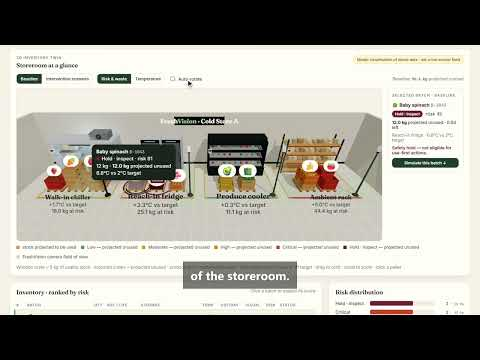

**🌐 Live prototype** (open in a new tab for the best experience: https://freshvision-nine.vercel.app/)

In [14]:
from IPython.display import IFrame, YouTubeVideo, display, Markdown
display(Markdown("**▶️ Demo video** (1:57, AI voice-over with subtitles)"))
display(YouTubeVideo("4cgehACaUok", width=800, height=450))
display(Markdown("**🌐 Live prototype** (open in a new tab for the best experience: https://freshvision-nine.vercel.app/)"))
display(IFrame("https://freshvision-nine.vercel.app/", width="100%", height=650))

<a name="limits"></a>
## 8. Limitations & roadmap

**What is implemented (prototype):** a browser-only static web app (React 18, Vite, TypeScript), in-browser image heuristics, an explainable configurable risk engine, the counterfactual simulator, rule-based recommendations, the 3D digital twin, and deployment on Vercel.

**Honest limitations**
- Risk weights, shelf lives and the Q10 ageing factor are **uncalibrated assumptions**.
- Image heuristics can be misled by shadows, glare, packaging and multi-coloured produce. They are **not** a trained spoilage model.
- All inventory, sensor and consumption values are **demo data**. There is no live sensor integration yet.
- The simulator projects **model outputs**. **No accuracy, waste-reduction or savings results are claimed.**

**Roadmap**
1. Collect and annotate real produce images.
2. Improve and validate visual-condition modelling (precision/recall on annotated indicators).
3. Integrate storage sensors and reliable inventory history.
4. Improve consumption forecasting.
5. Run a real-world pilot and measure waste outcomes against simulated actions.

---
**FreshVision — Don't detect waste. Prevent it before it happens.** · Team DeeDos